# 定义损失函数：传入参数向量（二元）

In [48]:
import torch
from torch.optim import SGD, Adagrad
import numpy as np
import matplotlib.pyplot as plt

# 定义二元二次损失函数：f(w) = 0.05*w0^2 + w1^2
# 梯度：∂f/∂w0 = 0.1*w0,  ∂f/∂w1 = 2*w1
# w0 方向曲率小（系数 0.05），w1 方向曲率大（系数 1）——典型的病态优化问题
def f(w):
    return 0.05 * w[0]**2 + w[1] ** 2

# 定义函数，实现梯度下降法

In [49]:
# 通用的梯度下降迭代流程
# 核心公式（不同优化器的 g(∇f, r) 实现不同）：
#   loss = f(w)
#   ∇f(w) = ∂loss/∂w
#   w = w - g(∇f, r)     —— g 取决于优化器策略
def gradient_descent(w, optimizer, n_iters):
    # 记录每一步的参数位置，用于后续绘制优化轨迹
    w0_list = []
    w1_list = []
    for i in range(n_iters):
        w0_list.append(w[0].item())
        w1_list.append(w[1].item())
        # 1. 前向传播：计算当前参数下的损失值 loss = f(w)
        loss = f(w)
        # 2. 反向传播：计算损失对各参数的梯度 ∇f(w)
        loss.backward()
        # 3. 根据梯度更新参数（不同优化器的更新策略不同）
        optimizer.step()
        # 4. 清零梯度，避免梯度累加（PyTorch 默认梯度是累加的）
        optimizer.zero_grad()
    return w0_list, w1_list

# 定义参数

In [50]:
# 训练超参数
lr = 0.9         # 学习率，故意设大以观察不同优化器的行为差异
n_iters = 500    # 迭代次数

# 初始参数点，选择远离最优点的位置以放大优化轨迹的区别
start_w = [-7.0, 2]

# 对比不同的优化器
## 1. SGD

In [51]:
# 使用 SGD 优化器
# 更新公式：w_{t+1} = w_t - lr * ∇f(w_t)
# SGD 对所有参数使用统一的学习率，在曲率差异大的损失面上容易震荡
sgd_w = torch.tensor(start_w, requires_grad=True)
optimizer = SGD([sgd_w], lr=lr)
sgd_w0_list, sgd_w1_list = gradient_descent(sgd_w, optimizer, n_iters)

# 2. AdaGrad

In [52]:
# 使用 AdaGrad 优化器
# 更新公式：
#   r_t = r_{t-1} + ∇f(w_t) ⊙ ∇f(w_t)    —— 累加历史梯度平方（逐元素）
#   w_{t+1} = w_t - lr / (√r_t + ε) ⊙ ∇f(w_t)   —— 用累加和的平方根缩放学习率
# 效果：
#   w1 方向梯度大 → 累加值大 → 有效学习率 lr/√r_t 变小，抑制震荡
#   w0 方向梯度小 → 累加值小 → 有效学习率保持较大，加速收敛
adagrad_w = torch.tensor(start_w, requires_grad=True)
optimizer = Adagrad([adagrad_w], lr=lr)
x0_list, x1_list = gradient_descent(adagrad_w, optimizer, n_iters)

print(x0_list, x1_list)

[-7.0, -6.099999904632568, -5.508719444274902, -5.04949426651001, -4.668196201324463, -4.339969158172607, -4.050979137420654, -3.792588710784912, -3.558971405029297, -3.3459725379943848, -3.1505014896392822, -2.970181703567505, -2.8031365871429443, -2.647850513458252, -2.5030770301818848, -2.367774486541748, -2.241060733795166, -2.1221790313720703, -2.01047420501709, -1.9053730964660645, -1.8063708543777466, -1.7130190134048462, -1.624916672706604, -1.541703462600708, -1.4630537033081055, -1.388671636581421, -1.3182873725891113, -1.2516539096832275, -1.1885441541671753, -1.128748893737793, -1.0720746517181396, -1.0183420181274414, -0.9673843383789062, -0.9190464615821838, -0.8731836080551147, -0.8296603560447693, -0.7883501052856445, -0.7491340637207031, -0.7119007110595703, -0.6765452027320862, -0.6429689526557922, -0.6110790967941284, -0.5807880759239197, -0.5520133376121521, -0.5246767997741699, -0.49870485067367554, -0.4740278124809265, -0.45057982206344604, -0.4282985329627991, -0

# 比对图

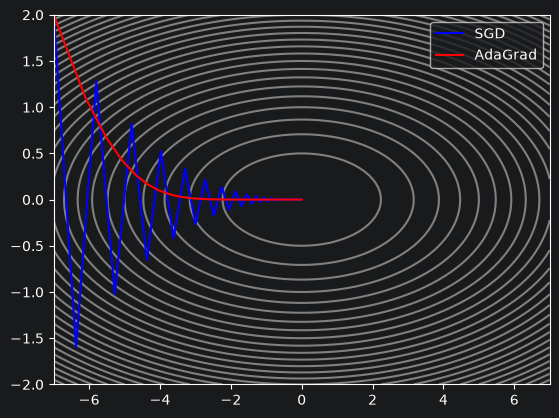

In [47]:
# 绘制损失函数 f(w) = 0.05*w0^2 + w1^2 的等高线及优化轨迹
# 等高线越密表示梯度 ||∇f|| 越大——w1 方向远比 w0 方向陡峭
x0, x1 = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
loss = f([x0, x1])
plt.contour(x0, x1, loss, colors='gray', levels=30)

# 蓝色轨迹：SGD w = w - lr*∇f —— w1 方向梯度过大导致剧烈震荡
plt.plot(sgd_w0_list, sgd_w1_list, color='b')
# 红色轨迹：AdaGrad w = w - lr/√(r+ε)*∇f —— 自适应压制 w1 步长，平稳下降
plt.plot(x0_list, x1_list, color='r')
plt.legend(['SGD', 'AdaGrad'])
plt.show()

# 总结
为每个参数自适应地调整学习率，对低频更新的参数使用较大学习率，高频更新的参数用较小学习率。

缺点：
- 因为h一直累加，学习越深入，更新的幅度就越小。如果无止境地学习，更新量就会变为0，完全不再更新。
- 当梯度为0时，会直接停止更新
